# Lab 09: Extracting Data from PDFs

*INFO 4617/5617 · Week 9 · Chapter 9, [Extracting Data from PDFs](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-09-pdfs.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

We'll take the City of Boulder's PDFs apart the way the chapter does: see what a page actually stores, sort pages into born-digital, scanned, and scanned with a text layer, pull text with pypdf and tables with pdfplumber, read a picture of a table with OCR, and check every extraction. We end with eight years of the city's sales and use tax, read from seven year-end revenue reports.

**The files:** the chapter's copies of the city's records, kept in the book's repository, so that a whole class doesn't hit the city's server at once. Only one step (Step 3) asks the city's portal itself, and in class only the instructor runs it.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. Step 0 imports pypdf, pdfplumber, and pytesseract; if one stops with `ModuleNotFoundError`, run `%conda install -y -c conda-forge pypdf pdfplumber pytesseract tesseract` once in a new cell, as the chapter's "Installing pypdf, pdfplumber, and pytesseract" says, then restart the kernel.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in and was run on 2026-10-21: the book's saved copies from GitHub, and, in Step 3, two live requests to the city's records portal. The PDFs don't change, so a rerun gives the same figures, except where library versions differ. This run used pypdf 6.21.2, pdfplumber 0.11.10, and Tesseract 5.3.4; the chapter's outputs came from pypdf 6.20.1 and Tesseract 5.5.3. Three outputs differ from the chapter's. In Step 7, Tesseract parsed 29 of Exhibit 3's 30 rows and set 1 aside, where the chapter reports 28 and 2. In Step 4, pypdf's layout mode keeps every word whole ("Council Chambers", "Carried"), where the chapter prints "C ham bers" and "Car r ied"; and in Step 2, page 3 of the December 2024 report has 2,781 characters, where the chapter prints 2,782. Those two come out the same with pypdf 6.20.1, so they aren't a version difference. Step 3's folder listing will change if the city adds a report. The lab follows the textbook at commit d9306b7. Every cell was run.

## Step 0 — Set up, and get the first file (5 minutes)

Import what the lab uses, and define the chapter's `HEADERS` and `get_saved_copy(name)`: it downloads one of the book's saved files from `BOOK_DATA`, `https://raw.githubusercontent.com/cuinfoscience/Web-Data-Science-Book/main/data/ch-09/`, into a `pdfs` folder the first time you ask, and after that returns the copy on disk. A PDF is bytes, not text, so save [`response.content`](https://requests.readthedocs.io/en/latest/user/quickstart/#binary-response-content), not `response.text`. Then get the December 2024 revenue report and print the libraries' versions, and Tesseract's: `pytesseract` runs a separate program, Tesseract, and a missing program shows up here as `TesseractNotFoundError`. The chapter's "This Chapter's Files" has the code.

In [1]:
# Import re, time, hashlib, Path (from pathlib), requests, pandas as pd, matplotlib.pyplot as plt, pypdf's PdfReader, pdfplumber, pytesseract
# Define BOOK_DATA, HEADERS (a User-Agent with your email, as in week 2), and PDF_DIR = Path("pdfs")
# Define get_saved_copy(name): if PDF_DIR / name doesn't exist, make the folder, download BOOK_DATA + name, and save the bytes
# Get "revenue-report-2024-12.pdf" as report_2024; print its size, the versions of pypdf, pdfplumber, pytesseract, and Tesseract
import re
import time
import hashlib
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import pypdf
import pdfplumber
import pytesseract
from pypdf import PdfReader

BOOK_DATA = "https://raw.githubusercontent.com/cuinfoscience/Web-Data-Science-Book/main/data/ch-09/"
HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
PDF_DIR = Path("pdfs")

def get_saved_copy(name):
    """Return the path of one of the book's saved files, downloading it the first time."""
    path = PDF_DIR / name
    if not path.exists():                  # download only the first time
        PDF_DIR.mkdir(exist_ok=True)
        response = requests.get(BOOK_DATA + name, headers=HEADERS, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content) # a PDF is bytes, so save the bytes as they came
    return path

report_2024 = get_saved_copy("revenue-report-2024-12.pdf")
print(report_2024, f"{report_2024.stat().st_size:,} bytes")
print("pypdf", pypdf.__version__, "| pdfplumber", pdfplumber.__version__, "| pytesseract", pytesseract.__version__)
print("Tesseract", pytesseract.get_tesseract_version())

pdfs/revenue-report-2024-12.pdf 723,920 bytes
pypdf 6.21.2 | pdfplumber 0.11.10 | pytesseract 0.3.13
Tesseract 5.3.4


<details>
<summary>💬 Discuss</summary>

- In week 2 we put contact information in the User-Agent. Who reads this one, now that the request goes to GitHub rather than to the city?
- Week 6's exercises cached a page's raw HTML before parsing it. What does `get_saved_copy()` save us, and the server, when we rerun a cell twenty times?
- Why does the book serve its own copies instead of sending a class of forty to the city's records portal?

</details>

## Step 1 — What a PDF page draws (5 minutes)

A PDF page is a list of drawing instructions: characters at coordinates, lines and rectangles, and images. Nothing in it says "word", "line", or "table"; every tool infers those from position. [pdfplumber](https://github.com/jsvine/pdfplumber) lists every object on a page with its position in points (1/72 inch) from the left edge (`x0`) and the top (`top`). Look at page 2, where the report's tables start. Then read what the file says about itself with pypdf's [`metadata`](https://pypdf.readthedocs.io/en/stable/user/metadata.html), and whether it is *tagged*, with a structure tree for screen readers. The chapter's "What's Inside a PDF" has more, including the drawing instructions themselves.

In [2]:
# Open report_2024 with pdfplumber; for page 2, print the page count and the page's width and height,
#   seven of page.chars (text, x0, top, fontname, size), and how many chars, lines, rects, and images it draws
# Open it with PdfReader as reader: print the metadata's title, subject, creator, and creation_date,
#   and whether reader.trailer["/Root"] holds "/StructTreeRoot" (a tagged PDF)
with pdfplumber.open(report_2024) as pdf:
    page = pdf.pages[1]  # the second page
    print(len(pdf.pages), "pages; this one is", page.width, "by", page.height, "points")
    for char in page.chars[1:8]:
        print(repr(char["text"]), round(char["x0"], 1), round(char["top"], 1), char["fontname"], round(char["size"], 1))
    print(len(page.chars), "characters,", len(page.lines), "lines,", len(page.rects), "rectangles,", len(page.images), "images")

reader = PdfReader(report_2024)
meta = reader.metadata
print(meta.title, "|", meta.subject, "|", meta.creator, "|", meta.creation_date)
print("tagged:", "/StructTreeRoot" in reader.trailer["/Root"])

15 pages; this one is 612.0 by 792.0 points
'C' 54.0 30.4 CALYKT+Arial-BoldMT 11.0
'i' 61.9 30.4 CALYKT+Arial-BoldMT 11.0
't' 65.0 30.4 CALYKT+Arial-BoldMT 11.0
'y' 68.8 30.4 CALYKT+Arial-BoldMT 11.0
' ' 74.9 30.4 CALYKT+Arial-BoldMT 11.0
'o' 78.0 30.4 CALYKT+Arial-BoldMT 11.0
'f' 84.6 30.4 CALYKT+Arial-BoldMT 11.0
2222 characters, 0 lines, 549 rectangles, 0 images
REVENUE REPORT | March 2018 | Acrobat PDFMaker 25 for Word | 2025-05-01 13:20:25-06:00
tagged: True


<details>
<summary>💬 Discuss</summary>

- The first characters spell "City of" one at a time, and the table's rules are hundreds of thin rectangles. What does a table finder have to rebuild before it can find a single cell?
- The subject of a report on December 2024 says March 2018. What else in a file's metadata would you hesitate to rely on, and what is the creator still good for?
- Week 4's XML and JSON store their structure in the file. What does a PDF store instead, and what does that cost the person who wants its data?

</details>

## Step 2 — What kind of PDF is it? (9 minutes)

Before extracting anything, sort the pages, because the right tool depends on how each was made. **Born-digital** pages have characters to extract; **scanned** pages are one image and no characters, so they need OCR; **scanned with a text layer** pages are one image plus text that someone's OCR already produced, of unknown quality. Write the chapter's `page_profile(path)`, which counts each page's characters of [`extract_text()`](https://pypdf.readthedocs.io/en/stable/user/extract-text.html) and its [`images`](https://pypdf.readthedocs.io/en/stable/user/extract-images.html), and run it on three files. Then ask the 2018 minutes who made them, and read their first lines. The chapter's "What Kind of PDF Is It?" has the routing table.

In [3]:
# Define page_profile(path): for each page of PdfReader(path), count len(page.extract_text()) and len(page.images); return both lists
# Print the two lists for revenue-report-2024-12.pdf, revenue-report-2018.pdf, and council-minutes-2018-12-04.pdf
# For the 2018 minutes (minutes): print the metadata's creator and creation_date, and the first three lines of page 1's text
def page_profile(path):
    """Count the characters of extracted text, and the images, on each page of a PDF."""
    reader = PdfReader(path)
    characters = []
    images = []
    for page in reader.pages:
        characters.append(len(page.extract_text()))  # how much text the page gives
        images.append(len(page.images))              # how many pictures it holds
    return characters, images

for name in ["revenue-report-2024-12.pdf", "revenue-report-2018.pdf", "council-minutes-2018-12-04.pdf"]:
    characters, images = page_profile(get_saved_copy(name))
    print(name)
    print("  characters:", characters)
    print("  images:    ", images)

minutes = PdfReader(get_saved_copy("council-minutes-2018-12-04.pdf"))
print(minutes.metadata.creator, "|", minutes.metadata.creation_date)
for line in minutes.pages[0].extract_text().splitlines()[:3]:
    print(line.strip())

revenue-report-2024-12.pdf
  characters: [1332, 2279, 2781, 648, 738, 393, 491, 1356, 1390, 676, 3429, 1519, 3797, 4624, 265]
  images:     [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]


revenue-report-2018.pdf
  characters: [1491, 1919, 143, 474, 42, 191, 374, 269, 907, 1273, 3048, 1334, 3031, 3964, 5569]
  images:     [1, 0, 2, 1, 1, 1, 3, 3, 2, 1, 0, 0, 0, 0, 0]


council-minutes-2018-12-04.pdf
  characters: [1718, 1869, 1729, 2381, 2776, 1706, 1665, 1673, 320]
  images:     [1, 1, 1, 1, 1, 1, 1, 1, 1]
Canon  | 2019-01-22 10:08:22-07:00
CITY OF BOULDER
CITY COTJNCIL MEETING
Municipal Building, 1777 Broadway


### ⏱ Microsprint (5 minutes, alone or in pairs)

A short version of Additional Exercise 5's quality check.

**Do:** run `page_profile()` on one of two files the chapter mentions but doesn't profile, `council-minutes-2000-12-19.pdf` or `revenue-report-2021-12.pdf`, and give each page a route from the chapter's table: born-digital (no image), scanned (an image and next to no text), or an image with text (test the text layer). Print who made the file, too: its metadata's `creator` and `producer`.
**Share:** your file, how many pages take each route, and which pages you'd send to OCR.

In [4]:
# Microsprint: profile one file and route each page: no image -> born-digital; an image and under 100 characters -> OCR;
#   an image and more text -> test the text layer. Count the pages on each route, list the OCR pages, and print creator and producer
scan_2000 = get_saved_copy("council-minutes-2000-12-19.pdf")
characters, images = page_profile(scan_2000)
routes = []
for chars, imgs in zip(characters, images):
    if imgs == 0:
        routes.append("born-digital")
    elif chars < 100:
        routes.append("OCR")
    else:
        routes.append("test the text layer")
print("characters:", characters)
print(pd.Series(routes).value_counts().to_string())
ocr_pages = []
for number, route in enumerate(routes, start=1):
    if route == "OCR":
        ocr_pages.append(number)
print("pages to send to OCR:", ocr_pages)
meta_2000 = PdfReader(scan_2000).metadata
print("creator:", meta_2000.creator, "| producer:", meta_2000.producer)

characters: [2207, 0, 0, 0, 1693, 1575, 0, 0, 0]
OCR                    6
test the text layer    3
pages to send to OCR: [2, 3, 4, 7, 8, 9]
creator: None | producer: iTextSharp 4.1.7 by 1T3XT


<details>
<summary>💬 Discuss</summary>

- How many pages of your file go to OCR? Would one character count for the whole file have told you which ones?
- The scanner's own OCR turned "COUNCIL" into "COTJNCIL". Why is a text layer you didn't make something to test rather than something to trust?
- Week 8 began with three checks for whether a page needs a browser. Which of today's checks plays the part of View Source, and which the part of the Network tab?

</details>

## Step 3 — Where the files came from: the city's portal (6 minutes)

**In class, only the instructor runs this cell.** On October 6, 2026, the city's server stopped answering after 13 to 17 requests in a row; a room of us running it at once would look like one client sending forty. Write it now, and run it at home. Nothing later in the lab needs it, so before Friday's **Run All Above**, comment it out (select its lines and press Ctrl+/ or Cmd+/), or a room of us will send it at once after all.

The saved copies came from the city's Laserfiche WebLink portal. Its folder page is a shell that JavaScript fills in, and the browser's Network tab shows where the list comes from: a POST to `GetFolderListing2` that sends a folder's number as JSON and gets JSON back. The city's server leaves out an intermediate certificate, so Python's default check fails with `CERTIFICATE_VERIFY_FAILED`; pass the book's bundle with [`verify=bundle`](https://requests.readthedocs.io/en/latest/user/advanced/#ssl-cert-verification), never `verify=False`. Then download one report, after a pause, and check what came back before trusting it: the content type, the five bytes `%PDF-` that start every PDF, and the file's SHA-256 hash against the book's `manifest.csv`, its record of where each copy came from. The chapter's "Getting the Files" and "Appendix: Technical Notes" have the code.

In [5]:
# In class, only the instructor runs this cell. Get boulder-ca-bundle.pem and manifest.csv with get_saved_copy(); read the manifest
# POST the folder page's JSON body (folder 194345) to PORTAL + "FolderListingService.aspx/GetFolderListing2" with verify=bundle;
#   print the folder's path, then each entry's entryId, name, and kind (type 0 is a folder; else data[1] is its page count)
# Sleep 30 s; GET ElectronicFile.aspx for docid 194397; print Content-Type, size, first 5 bytes; compare its SHA-256 with the manifest
bundle = get_saved_copy("boulder-ca-bundle.pem")
manifest = pd.read_csv(get_saved_copy("manifest.csv"))
PORTAL = "https://documents.bouldercolorado.gov/WebLink/"

body = {"repoName": "LF8PROD2", "folderId": 194345, "getNewListing": True,
        "start": 0, "end": 100, "sortColumn": "", "sortAscending": True}
response = requests.post(PORTAL + "FolderListingService.aspx/GetFolderListing2",
                         json=body, headers=HEADERS, timeout=60, verify=bundle)
response.raise_for_status()
folder = response.json()["data"]
print(folder["path"], "|", folder["totalEntries"], "entries")
for entry in folder["results"]:
    if entry["type"] == 0:
        kind = "folder"
    else:
        kind = f"{entry['data'][1]} pages"
    print(entry["entryId"], entry["name"], f"({kind})")

time.sleep(30)  # wait between requests to the city's server
docid = 194397  # Revenue Report 2024.12
url = PORTAL + f"ElectronicFile.aspx?docid={docid}&dbid=0&repo=LF8PROD2"
response = requests.get(url, headers=HEADERS, timeout=120, verify=bundle)
response.raise_for_status()
print(response.headers["Content-Type"], len(response.content), response.content[:5])

record = manifest[manifest["docid"] == docid].iloc[0]  # the manifest's row for this document
print(record["file"], "retrieved", record["retrieved_utc"])
print("same file as the book's copy:", hashlib.sha256(response.content).hexdigest() == record["sha256"])

\Central Records\Finance\Reports\Revenue Reports | 7 entries
194346 2021 (folder)
194359 2022 (folder)
194372 2023 (folder)
194385 2024 (folder)
194398 Revenue Report 2018 (15 pages)
194399 Revenue Report 2019 (14 pages)
194400 Revenue Report 2020 (16 pages)


application/pdf 723920 b'%PDF-'
revenue-report-2024-12.pdf retrieved 2026-10-06T06:24:30Z
same file as the book's copy: True


<details>
<summary>💬 Discuss</summary>

- Week 8 found hidden APIs in the Network tab. Which parts of this request (the folder number, `LF8PROD2`, the body) would break first if the city upgraded its portal?
- Python's default check failed and the book's bundle passed. Why is `verify=False` the wrong fix, even for public records?
- The manifest records each file's address, retrieval time, and hash. What could a reader of your project check with it that they couldn't without it?

</details>

## Step 4 — Text two ways: pypdf and pdfplumber (9 minutes)

The minutes of December 5, 2024 were written in Word and saved as PDF, so every page has characters. [pypdf](https://pypdf.readthedocs.io/) writes them out in the order the page draws them; its `extraction_mode="layout"` places each piece by its position instead. [pdfplumber](https://github.com/jsvine/pdfplumber#extracting-text) starts from where each character ends up, grouping characters into words when the gap is under 3 points (`x_tolerance`) and words into lines when their tops line up. Print the top of page 1 all three ways and compare. The chapter's "Text with pypdf" shows, in the page's drawing instructions, why Word's first letters break off.

In [6]:
# Open council-minutes-2024-12-05.pdf with PdfReader as minutes_2024; text = page 1's extract_text(); print its first 13 lines
# Print the first lines of extract_text(extraction_mode="layout"), skipping blank lines and shrinking runs of spaces to one
# Open the same file with pdfplumber and print the first 11 lines of page 1's extract_text()
minutes_2024 = PdfReader(get_saved_copy("council-minutes-2024-12-05.pdf"))
text = minutes_2024.pages[0].extract_text()
print("--- pypdf, plain")
for line in text.splitlines()[:13]:
    print(line.rstrip())

print("--- pypdf, layout")
layout = minutes_2024.pages[0].extract_text(extraction_mode="layout")
for line in layout.splitlines()[:18]:
    if line.strip():
        print(" ".join(line.split()))

print("--- pdfplumber")
with pdfplumber.open(get_saved_copy("council-minutes-2024-12-05.pdf")) as pdf:
    for line in pdf.pages[0].extract_text().splitlines()[:11]:
        print(line)

--- pypdf, plain
P age 1
CI
TY COUNCIL MEETING
Council Chambers
Thursday, December 5, 2024
MINUTES
1. C
all to Order and Roll Call:
M
ayor Brockett called the meeting to order at 6:00 p.m.
C
ouncil Members present: Benjamin, Brockett, Folkerts, Marquis, Schuchard,
Speer, Wallach, Winer
--- pypdf, layout
CITY COUNCIL MEETING
Council Chambers
Thursday, December 5, 2024
MINUTES
1. Call to Order and Roll Call:
Mayor Brockett called the meeting to order at 6:00 p.m.
Council Members present : Benjamin, Brockett, Folkerts, Marquis, Schuchard,
Speer, Wallach, Winer
Virtually present: Adams
Motion Made By/Seconded Vote
Motion to AMEND the agenda to: Wallach / Benjamin Carried 9:0
--- pdfplumber
CITY COUNCIL MEETING
Council Chambers
Thursday, December 5, 2024
MINUTES
1. Call to Order and Roll Call:
Mayor Brockett called the meeting to order at 6:00 p.m.
Council Members present: Benjamin, Brockett, Folkerts, Marquis, Schuchard,
Speer, Wallach, Winer
Virtually present: Adams
Motion Made By/Seconde

### ⏱ Microsprint (5 minutes, alone or in pairs)

A short version of Additional Exercise 4, on a table instead of prose.

**Do:** extract page 2 of `report_2024`, the page with the sales and use tax summary, all three ways, and print, from each, only the lines that hold `"Total Sales"` or `"current economic activity"`.
**Share:** whether the three extractions agree on these rows, and what a pattern that reads one row per line would take as the subtotal's label, "Total Sales & Use Tax based on current economic activity", which wraps onto two lines on the page.

In [7]:
# Microsprint: extract page 2 of report_2024 with pypdf (plain and layout) and pdfplumber;
#   from each, print only the lines that contain "Total Sales" or "current economic activity"
summary_texts = {
    "pypdf, plain": PdfReader(report_2024).pages[1].extract_text(),
    "pypdf, layout": PdfReader(report_2024).pages[1].extract_text(extraction_mode="layout"),
}
with pdfplumber.open(report_2024) as pdf:
    summary_texts["pdfplumber"] = pdf.pages[1].extract_text()

for tool, page_text in summary_texts.items():
    print("---", tool)
    for line in page_text.splitlines():
        if "Total Sales" in line or "current economic activity" in line:
            print(" ".join(line.split()))

--- pypdf, plain
Total Sales & Use Tax based on
current economic activity $172,401,668 $171,006,199 -$1,395,469 -0.81% -0.81%
Total Sales and Use Tax $175,517,129 $173,908,431 -$1,608,698 -0.92% -0.92%
--- pypdf, layout
Total Sales & Use Tax based on
current economic activity $172,401,668 $171,006,199 -$1,395,469 -0.81% -0.81%
Total Sales and Use Tax $175,517,129 $173,908,431 -$1,608,698 -0.92% -0.92%
--- pdfplumber
Total Sales & Use Tax based on
current economic activity $172,401,668 $171,006,199 -$1,395,469 -0.81% -0.81%
Total Sales and Use Tax $175,517,129 $173,908,431 -$1,608,698 -0.92% -0.92%


<details>
<summary>💬 Discuss</summary>

- pypdf's plain mode broke lines. The chapter says layout mode breaks words instead ("C ham bers"), but ours didn't. What would you check before relying on either mode's output for a new file?
- In the microsprint all three tools agreed, and all three put the subtotal's figures on its label's second line. What would a one-row-per-line pattern call that row, and which check would notice?
- pypdf printed "P age 1" first, though the page number sits at the bottom. What does that tell you about the order a PDF is drawn in?

</details>

## Step 5 — Repair the text, then find things in it (9 minutes)

Repair what pypdf broke with [regular expressions](https://docs.python.org/3/library/re.html), matching what the extraction produced rather than what the page shows: a pattern for "Page 1" would miss "P age 1". Write the chapter's `clean_page_text(raw_text)`. It drops the page number, rejoins a first letter that Word drew apart ("M" and "ayor"), and collapses runs of spaces and tabs but **not** newlines, because a heading is recognizable by sitting on its own line. Then join and clean all eight pages, and run the chapter's five patterns with [`re.findall()`](https://docs.python.org/3/library/re.html#re.findall). The chapter's "Cleanup Strategies" and "Regular Expressions for PDF Text" explain each one.

In [8]:
# Define clean_page_text(raw_text): re.sub away ^P ?age \d+ lines (MULTILINE); join \b([A-Z]{1,2})\n before a letter;
#   collapse [ \t]+ to one space; strip each line and drop empty ones. Print the first 8 cleaned lines of page 1 (text)
# Clean all eight pages joined by "\n" into full_text; with re.findall print: dates in words, dates with slashes,
#   the first and last clock times and how many, (Carried|Failed) n:n tallies, and dollar amounts
def clean_page_text(raw_text):
    """Clean text that pypdf extracted from a page of the council minutes, keeping its line breaks."""
    # Drop the page number, which pypdf reads from these minutes as "P age 1"
    text = re.sub(r'^P ?age \d+[ \t]*$', '', raw_text, flags=re.MULTILINE)
    # Rejoin a first letter that Word drew apart from the rest of its word: "M" and "ayor" become "Mayor"
    text = re.sub(r'\b([A-Z]{1,2})\n(?=[A-Za-z])', r'\1', text)
    # Collapse runs of spaces and tabs, but NOT newlines
    text = re.sub(r'[ \t]+', ' ', text)
    kept = []
    for line in text.split('\n'):
        line = line.strip()
        if line:
            kept.append(line)
    return '\n'.join(kept)

for line in clean_page_text(text).splitlines()[:8]:
    print(line)
print()

page_texts = []
for page in minutes_2024.pages:
    page_texts.append(page.extract_text())
full_text = clean_page_text("\n".join(page_texts))

MONTH = r'(?:January|February|March|April|May|June|July|August|September|October|November|December)'
print(re.findall(MONTH + r' \d{1,2}, \d{4}', full_text))
print(re.findall(r'\d{1,2}/\d{1,2}/\d{2,4}', full_text))
times = re.findall(r'\d{1,2}:\d{2} [ap]\.m\.', full_text)
print(times[0], "to", times[-1], f"({len(times)} times in all)")
print(re.findall(r'(Carried|Failed) (\d+):(\d+)', full_text))
print(re.findall(r'\$[\d,]+(?:\.\d{2})?', full_text))

CITY COUNCIL MEETING
Council Chambers
Thursday, December 5, 2024
MINUTES
1. Call to Order and Roll Call:
Mayor Brockett called the meeting to order at 6:00 p.m.
Council Members present: Benjamin, Brockett, Folkerts, Marquis, Schuchard,
Speer, Wallach, Winer

['December 5, 2024', 'November 5, 2024', 'November 5, 2024']
['12/05/24', '12/19/24']
6:00 p.m. to 10:43 p.m. (12 times in all)
[('Carried', '9', '0'), ('Carried', '9', '0')]
['$20,000,000']


### ⏱ Microsprint (5 minutes, alone or in pairs)

The chapter's advice, "check a repair written for one file on the next, and print what it changed", cut to five minutes.

**Do:** on every page of `council-minutes-2023-12-07.pdf`, find each place where `clean_page_text()`'s second rule (`\b([A-Z]{1,2})\n` before a letter) would join two lines. Count the joins. A join is suspicious when its capital letters don't start a word, that is, when the character before them isn't a space or a line break; print only those, as the word the join would make. (The other joins include the first names of members of the public who spoke, so print counts, not words.)
**Share:** how many joins, how many look suspicious, and which of those is really wrong.

In [9]:
# Microsprint: for each page of council-minutes-2023-12-07.pdf, find every match of the join rule with re.finditer; count them
#   For a match whose capitals follow a character other than whitespace, print the page and the word the join makes
JOIN = re.compile(r"\b([A-Z]{1,2})\n(?=[A-Za-z])")
minutes_2023 = PdfReader(get_saved_copy("council-minutes-2023-12-07.pdf"))
joins = 0
for number, page in enumerate(minutes_2023.pages, start=1):
    page_text = page.extract_text()
    for match in JOIN.finditer(page_text):
        joins += 1
        before = page_text[:match.start()]
        if before and not before[-1].isspace():          # the capitals don't start a word
            word_start = re.split(r"\s", before)[-1]     # what the word had before the capitals
            word_end = page_text[match.end():].split()[0]
            print("page", number, ":", word_start + match.group(1) + word_end)
print(joins, "joins in all")

page 1 : In-Person
page 3 : A-FWallach
page 3 : In-Person:
30 joins in all


<details>
<summary>💬 Discuss</summary>

- The join rule was right every time on the December 5 minutes and wrong at least once here. When has a repair been tested enough to run on a hundred files?
- The tally pattern found two votes, both in the motion tables. How would you find out how many votes it missed, such as "by a vote of 9:0"?
- Week 7 dropped stopwords before counting words. What else would a count of a topic word like "housing" need before you compared one meeting with another?

</details>

## Step 6 — Tables with pdfplumber (11 minutes)

pdfplumber's [table finder](https://github.com/jsvine/pdfplumber#extracting-tables) rebuilds a grid from the page's rules and the sides of its rectangles (the *lines* strategy), and makes a cell wherever rules close a box. Run [`find_tables()`](https://github.com/jsvine/pdfplumber#extracting-tables) on the summary page, and check its first table against the page with `search()`: the totals row has no vertical rules beside it, so it falls outside the table, and nothing raises an error. Then fix it as the chapter does: give the columns yourself as `explicit_vertical_lines` (the left and right edges of the cells it did find), keep the page's horizontal rules, and crop just below the totals row. Last, turn the rows into a DataFrame with the chapter's `summary_frame()`, naming the columns by position and turning the figures into numbers with `pd.to_numeric()` once the dollar signs and commas are gone, as week 6 did with a scraped table. The chapter's "Finding Tables" lists every table setting.

In [10]:
# Open report_2024 with pdfplumber as report; summary_page = page 2; print each found table's rounded bbox and row count
# default_rows = the first table's extract(); print its last row, and compare the table's bottom with the "Total Sales and Use Tax" row's
# Fix: explicit vertical lines at every cell's left and right edge, horizontal_strategy "lines", the page cropped to 395 points
# Define summary_frame(rows, columns, label="source") as the chapter does; build summary_df and print source and ytd_2024
report = pdfplumber.open(report_2024)  # closed at the end of this step
summary_page = report.pages[1]
tables = summary_page.find_tables()
for table in tables:
    edges = []
    for edge in table.bbox:
        edges.append(round(edge))
    print(edges, len(table.rows), "rows")

default_rows = tables[0].extract()
print(default_rows[-1][:6])
total_row = summary_page.search("Total Sales and Use Tax")[0]
print("the table ends at", round(tables[0].bbox[3]), "and the totals row runs from", round(total_row["top"]), "to", round(total_row["bottom"]))

first = tables[0]
edges = set()
for cell in first.cells:
    edges.add(round(cell[0], 2))  # the cell's left edge
    edges.add(round(cell[2], 2))  # and its right edge
edges = sorted(edges)
settings = {"vertical_strategy": "explicit", "explicit_vertical_lines": edges, "horizontal_strategy": "lines"}
area = summary_page.crop((first.bbox[0], first.bbox[1], first.bbox[2], 395))  # below the totals row, above the footnote
fixed_rows = area.extract_table(settings)
print(len(default_rows), "rows before,", len(fixed_rows), "after")
print(fixed_rows[-1][:6])

def summary_frame(rows, columns, label="source"):
    """Turn the rows of a table of labeled figures into a DataFrame, keeping rows with a label and a first figure."""
    figure_columns = []
    for name in columns:
        if name != label:
            figure_columns.append(name)
    first_figure = figure_columns[0]

    records = []
    for row in rows:
        if not row[columns[label]] or not row[columns[first_figure]]:
            continue  # a header row or a section title
        record = {}
        for name, position in columns.items():
            record[name] = row[position]
        records.append(record)
    frame = pd.DataFrame(records)
    frame[label] = frame[label].str.replace("\n", " ")  # a label that wraps becomes one line
    for name in figure_columns:
        frame[name] = pd.to_numeric(frame[name].str.replace(r"[$,%]", "", regex=True))
    return frame

summary_df = summary_frame(fixed_rows, {"source": 1, "ytd_2023": 3, "ytd_2024": 4, "change": 5, "pct_change": 7})
report.close()
print(summary_df[["source", "ytd_2024"]].to_string(index=False))

[54, 188, 588, 375] 12 rows
[60, 203, 232, 231] 2 rows
[54, 449, 577, 632] 13 rows
[459, 470, 505, 495] 2 rows
['Use Tax Audit Revenue', None, '1,498,943', None, '643,062', '-855,881']
the table ends at 375 and the totals row runs from 380 to 391


12 rows before, 13 after
['', 'Total Sales and Use Tax', '', '$175,517,129', '$173,908,431', '-$1,608,698']
                                                  source  ytd_2024
                                               Sales Tax 139069840
                                 Rec MJ Additional 3.5%*   1184018
                                        Business Use Tax   9855472
                                    Construction Use Tax  14930902
                                   Motor Vehicle Use Tax   5965968
Total Sales & Use Tax based on current economic activity 171006199
                                 Sales Tax Audit Revenue   2259170
                                   Use Tax Audit Revenue    643062
                                 Total Sales and Use Tax 173908431


### ⏱ Microsprint (6 minutes, alone or in pairs)

A short version of Additional Exercise 2, on another year. The chapter says the other reports' tables have different rules; does its fix carry over?

**Do:** open one other year-end report (`revenue-report-2018.pdf`, `-2019.pdf`, `-2020.pdf`, `-2021-12.pdf`, `-2022-12.pdf`, or `-2023-12.pdf`); its summary is on page 2, except 2020's, which is on page 3. Apply the fix, changing one thing: instead of cropping at 395 points, crop 3 points below the bottom of the `"Total Sales and Use Tax"` row that `search()` finds. Print the number of rows before and after, and the totals row.
**Share:** your year, whether the totals row came back, and its two figures (the year before, and this year).

In [11]:
# Microsprint: for one other report's summary page, find_tables(); take the first table's cell edges as explicit vertical lines
#   crop from the table's top to 3 points below the "Total Sales and Use Tax" row from search(), and extract_table(settings)
#   print the rows before and after, and the non-empty cells of the last row
with pdfplumber.open(get_saved_copy("revenue-report-2018.pdf")) as pdf:
    page = pdf.pages[1]
    first_2018 = page.find_tables()[0]
    edges_2018 = set()
    for cell in first_2018.cells:
        edges_2018.add(round(cell[0], 2))
        edges_2018.add(round(cell[2], 2))
    settings_2018 = {"vertical_strategy": "explicit", "explicit_vertical_lines": sorted(edges_2018), "horizontal_strategy": "lines"}
    total_2018 = page.search("Total Sales and Use Tax")[0]
    area_2018 = page.crop((first_2018.bbox[0], first_2018.bbox[1], first_2018.bbox[2], total_2018["bottom"] + 3))
    rows_2018 = area_2018.extract_table(settings_2018)
print(len(first_2018.rows), "rows before,", len(rows_2018), "after")
last_cells = []
for cell in rows_2018[-1]:
    if cell:
        last_cells.append(cell)
print(last_cells)

13 rows before, 16 after
['Total Sales and Use Tax', '$134,538,892', '$140,648,710', '$6,109,818', '4.54%']


<details>
<summary>💬 Discuss</summary>

- The default finder dropped the totals row and raised nothing. What told us, and what would have told us if we hadn't looked at the page?
- Did the fix carry over to your year? Line up the class's totals: what do you notice about a year that two reports both print?
- Week 6's `pd.read_html()` turned an HTML table into a DataFrame in one call. What does HTML's `<td>` give you for free that a PDF table doesn't?

</details>

## Step 7 — No text layer: OCR (11 minutes)

*Optical character recognition* turns a picture of text into characters. [pytesseract](https://github.com/madmaze/pytesseract) runs Tesseract on a Pillow image, which pypdf hands you as `page.images[0].image`. First, page 7 of the December 2018 minutes, where the scanner's own text layer turned the motion into "CouNcrr, Mnunrn WnlvnR MovED To ADopr": read the image again and print the lines that hold "MOVED" or "PASSED". Then Exhibit 3 of the December 2024 report, a picture of a table under a note offering "a screen readable version" on request. Convert it to grayscale and read it with `config="--psm 6"`, the [page segmentation mode](https://tesseract-ocr.github.io/tessdoc/ImproveQuality.html#page-segmentation-method) for one uniform block of text. Parse each row with the chapter's `ROW` pattern, setting aside lines with a year that don't parse, and check each row: its twelve months should add up to its total. Here the chapter's loop becomes a function, `parse_ocr_rows(lines)`, so the microsprint can rerun it. The chapter's "When There Is No Text Layer: OCR" has the confidence scores too, and why they mislead.

In [12]:
# OCR page 7's one image of the 2018 minutes (minutes, from Step 2) with image_to_string; print its size and the MOVED/PASSED lines
# exhibit_3 = page 15's image of report_2024, .convert("L"); ocr_lines = image_to_string(exhibit_3, config="--psm 6").splitlines()
# Define NUMBER, ROW (from the chapter), ocr_dollars(figure), and parse_ocr_rows(lines) -> (rows parsed, lines set aside)
# Print how many rows parsed and were set aside, the start of each set-aside line, and the largest gap between months and total
scan = minutes.pages[6].images[0].image
print(scan.size, "pixels")
for line in pytesseract.image_to_string(scan).splitlines():
    if "MOVED" in line or "PASSED" in line:
        print(line)
print()

exhibit_3 = PdfReader(report_2024).pages[14].images[0].image.convert("L")
ocr_lines = pytesseract.image_to_string(exhibit_3, config="--psm 6").splitlines()
print(exhibit_3.size, "pixels,", len(ocr_lines), "lines of text")

NUMBER = r"[—–-]?\d[\d.,]*"  # a figure as OCR may read it, with a stray dash, or periods for commas
# A row: an optional category name, a year, then 13 figures (twelve months and the year's total)
ROW = re.compile(r"^(?P<label>[A-Za-z ]*?)\s*(?P<year>20\d\d)\s+(?P<figures>(?:" + NUMBER + r"\s+){13})")

def ocr_dollars(figure):
    """'8.832.480' -> 8832480. The table's dollar figures are whole and positive, so every other character can go."""
    return int(re.sub(r"\D", "", figure))

def parse_ocr_rows(lines):
    """The chapter's loop over Exhibit 3's OCR lines, as a function: return the parsed rows and the lines set aside."""
    rows = []       # the rows that parsed
    set_aside = []  # lines with a year that didn't parse
    category = None
    for line in lines:
        match = ROW.match(line)
        if not match:
            if re.search(r"\b20\d\d\b", line):
                set_aside.append(line)
            continue
        if match["label"].strip():
            category = match["label"].strip()  # each category's name starts its first row
        figures = []
        for figure in match["figures"].split():
            figures.append(ocr_dollars(figure))
        rows.append({"category": category, "year": int(match["year"]), "months": figures[:12], "total": figures[12]})
    return rows, set_aside

ocr_rows, set_aside = parse_ocr_rows(ocr_lines)
print(len(ocr_rows), "rows parsed;", len(set_aside), "set aside")
for line in set_aside:
    print(" ".join(line.split()[:6]))
largest_gap = 0
for row in ocr_rows:
    largest_gap = max(largest_gap, abs(sum(row["months"]) - row["total"]))
print("largest gap between the months and the total:", largest_gap, "dollars")

(2556, 3291) pixels


COUNCIL MEMBER WEAVER MOVED TO ADOPT ORDINANCE 8302
MORZEL SECONDED THE MOTION. THE MOTION PASSED 8:1 AT 9:08 P.M.



(2545, 1331) pixels, 43 lines of text
29 rows parsed; 1 set aside
” 2022 489,417 405,726 646,263 552,449
largest gap between the months and the total: 2 dollars


### ⏱ Microsprint (5 minutes, alone or in pairs)

Change one parameter: the page segmentation mode.

**Do:** read `exhibit_3` again with `--psm 4` (one column of text of varying sizes) or `--psm 3` (Tesseract's default, which finds the layout itself), run `parse_ocr_rows()` on the lines, and print the number of lines, rows parsed, rows set aside, and the largest gap. Time it with `time.time()`.
**Share:** your mode, its three counts, its largest gap, and how many seconds it took.

In [13]:
# Microsprint: for --psm 4 (or 3), OCR exhibit_3 again, parse the lines with parse_ocr_rows(), and print
#   the number of lines, rows parsed, rows set aside, the largest gap between months and total, and the seconds it took
for psm in ["4", "3"]:
    started = time.time()
    lines = pytesseract.image_to_string(exhibit_3, config=f"--psm {psm}").splitlines()
    rows, aside = parse_ocr_rows(lines)
    gaps = []
    for row in rows:
        gaps.append(abs(sum(row["months"]) - row["total"]))
    print(f"--psm {psm}:", len(lines), "lines,", len(rows), "rows parsed,", len(aside), "set aside,",
          "largest gap", max(gaps), "dollars,", round(time.time() - started, 1), "seconds")

--psm 4: 45 lines, 29 rows parsed, 1 set aside, largest gap 2 dollars, 6.1 seconds


--psm 3: 60 lines, 30 rows parsed, 0 set aside, largest gap 2 dollars, 5.9 seconds


<details>
<summary>💬 Discuss</summary>

- Which mode parsed the most rows? Would you choose a mode by that count alone, or by what the checks say about the rows it parsed?
- Every parsed row adds up within $2. Name an OCR error that a row's sum can't catch.
- Chapter 9 calls a picture of a table the extreme case of soft enclosure. In week 3's terms, who is fenced out by it, and what does it cost them to get back in?

</details>

## Step 8 — Check the extractions (7 minutes)

Extraction fails without errors, so write the checks as a function that returns a list of problems, the chapter's `check_summary(table)`: **count** the rows the page shows (nine), and check the **sums** (the five sources add up to the subtotal, and the subtotal and the two audit rows to the total, within $5 of rounding). Run it on the fixed table and on the default one. Then two more checks: **two documents agree** (OCR's 2024 total, from the picture of Exhibit 3, against the summary page's text), and **a sample coded by hand**: who was present at the December 5, 2024 roll call, measured as [precision and recall](https://en.wikipedia.org/wiki/Precision_and_recall) against the nine members the page names. The chapter's "Checking an Extraction" lists eight checks, cheapest first.

In [14]:
# Define check_summary(table, tolerance=5): problems if not 9 rows or a total's label is missing; then, for each year,
#   if the five sources don't add up to the subtotal, or subtotal + the two audit rows don't add up to the total. Return the list
# Run it on summary_df and on default_df = summary_frame(default_rows, {"source": 0, "ytd_2023": 2, "ytd_2024": 4, "change": 5, "pct_change": 6})
# Compare OCR's TOTAL row for 2024 with summary_df's total; then precision and recall of the names after "present:" on page 1 (text)
def check_summary(table, tolerance=5):
    """Check the revenue summary table's figures against each other; return one line per failed check."""
    problems = []
    if len(table) != 9:  # the page shows nine rows of figures
        problems.append(f"expected 9 rows of figures, found {len(table)}")
    figures = table.set_index("source")
    subtotal = "Total Sales & Use Tax based on current economic activity"
    total = "Total Sales and Use Tax"
    for label in [subtotal, total]:
        if label not in figures.index:
            problems.append(f"no row labeled {label!r}")
    if problems:
        return problems  # the sums below need every row
    for year in ["ytd_2023", "ytd_2024"]:
        sources = figures[year].iloc[:5].sum()  # the five sources above the subtotal
        if abs(sources - figures.loc[subtotal, year]) > tolerance:
            problems.append(f"{year}: the sources add up to {sources:,}, not {figures.loc[subtotal, year]:,}")
        audits = figures.loc["Sales Tax Audit Revenue", year] + figures.loc["Use Tax Audit Revenue", year]
        if abs(figures.loc[subtotal, year] + audits - figures.loc[total, year]) > tolerance:
            problems.append(f"{year}: the subtotal and audit revenue don't add up to the total")
    return problems

default_df = summary_frame(default_rows, {"source": 0, "ytd_2023": 2, "ytd_2024": 4, "change": 5, "pct_change": 6})
print("fixed table:  ", check_summary(summary_df))
print("default table:", check_summary(default_df))

text_total = summary_df.set_index("source").loc["Total Sales and Use Tax", "ytd_2024"]
for row in ocr_rows:
    if row["category"] == "TOTAL" and row["year"] == 2024:
        print("OCR total", f"{row['total']:,}", "| text total", f"{text_total:,}", "| match:", row["total"] == text_total)

# Coded by hand from the page: eight members in the room, and one online
present_by_hand = {"Adams", "Benjamin", "Brockett", "Folkerts", "Marquis", "Schuchard", "Speer", "Wallach", "Winer"}
match = re.search(r"present:\s*(.*)$", text, re.IGNORECASE | re.MULTILINE)
present_found = set()
for name in match.group(1).split(","):
    if name.strip():
        present_found.add(name.strip())
correct = present_found & present_by_hand
print("precision:", round(len(correct) / len(present_found), 2), "| recall:", round(len(correct) / len(present_by_hand), 2))
print("missed:", sorted(present_by_hand - present_found))

fixed table:   []
default table: ['expected 9 rows of figures, found 8', "no row labeled 'Total Sales and Use Tax'"]
OCR total 173,908,431 | text total 173,908,431 | match: True
precision: 1.0 | recall: 0.56
missed: ['Adams', 'Speer', 'Wallach', 'Winer']


<details>
<summary>💬 Discuss</summary>

- Precision was perfect and recall was 0.56. Which of the two would a quick look at the output have shown you, and why?
- The sums say we copied the city's figures faithfully. Why don't they say the figures are right?
- The chapter's AI parser, Docling, wrote a complete-looking Exhibit 3 with two rows under the wrong label. Which of today's checks would you run on a parser's table first, and which would miss a wrong label?

</details>

## Step 9 — Seven reports, one time series (10 minutes)

The chapter's case study: total sales and use tax from all seven year-end reports. The table's rules differ from year to year, but one row is all we need, so read it by position. `find_summary_page(pdf)` finds the page by the sentence it begins with ("This report provides"), not by its number, since 2020's is on page 3. `row_words(page, label)` uses [`search()`](https://github.com/jsvine/pdfplumber#the-pdfplumberpage-class) to find the label and crops a strip as tall as its line; `to_number()` reads "$134,538,892", "(1,145,528)", and "-$1,608,698". Each row gives two years, the year before and this one, and its own change column is a free check. Keep both years from every report, compare the years printed twice, and plot each year's latest printing. The chapter's "Case Study: Boulder Revenue Reports" has the code and the figure.

14 figures from 7 reports; 0 change columns that don't check
      count        min        max  difference
year                                         
2018      2  140609751  140648710       38959
2019      2  141954650  141954650           0
2020      2  135195413  135195413           0
2021      2  152302653  152302653           0
2022      2  169112615  169112615           0
2023      2  175517129  175517129           0
          total  change_pct
year                       
2017  134538892         NaN
2018  140609751        4.51
2019  141954650        0.96
2020  135195413       -4.76
2021  152302653       12.65
2022  169112615       11.04
2023  175517129        3.79
2024  173908431       -0.92


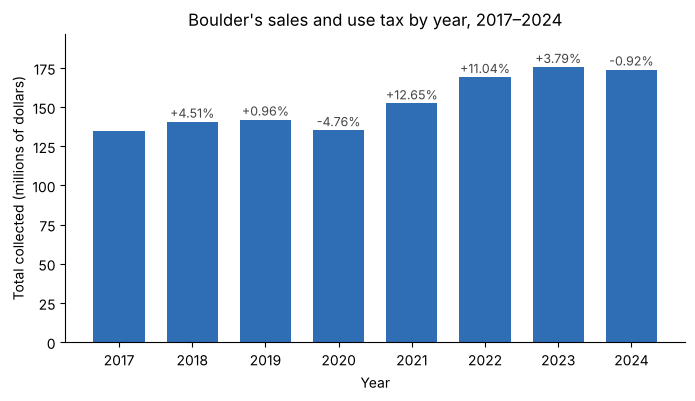

In [15]:
# Define find_summary_page(pdf), row_words(page, label), and to_number(text) as the chapter does
# For each of the seven REPORTS: the two years from search(r"(20\d\d) +(20\d\d)"), and the totals row's first three figures;
#   print any report whose change column doesn't check; keep both years' totals in a DataFrame, totals
# Show the years printed twice and how far apart they are; keep each year's latest printing; plot it as bars, labeled with the change
REPORTS = ["revenue-report-2018.pdf", "revenue-report-2019.pdf", "revenue-report-2020.pdf",
           "revenue-report-2021-12.pdf", "revenue-report-2022-12.pdf",
           "revenue-report-2023-12.pdf", "revenue-report-2024-12.pdf"]

def find_summary_page(pdf):
    """Return the page of a revenue report that holds the sales and use tax summary, or None."""
    for page in pdf.pages[:4]:
        if "This report provides" in (page.extract_text() or ""):
            return page
    return None

def row_words(page, label):
    """Return the words to the right of label, on the line where label is."""
    found = page.search(label)[0]
    line = page.crop((0, found["top"] - 1, page.width, found["bottom"] + 1))
    words = []
    for word in line.extract_words():
        if word["x0"] > found["x1"]:  # the word starts right of where the label ends
            words.append(word["text"])
    return words

def to_number(text):
    """Turn a figure such as "$134,538,892", "(1,145,528)", or "-$1,608,698" into an int."""
    negative = text.startswith(("(", "-"))
    value = int(re.sub(r"[^\d]", "", text))
    if negative:
        return -value
    return value

totals = []
unchecked = []  # reports whose change column doesn't check
for name in REPORTS:
    with pdfplumber.open(get_saved_copy(name)) as pdf:
        page = find_summary_page(pdf)
        years = page.search(r"(20\d\d) +(20\d\d)")[0]["groups"]
        figures = row_words(page, "Total Sales and Use Tax")
        earlier, this, change = to_number(figures[0]), to_number(figures[1]), to_number(figures[2])
    if this - earlier != change:
        unchecked.append(name)
        print(f"{name}: {this:,} - {earlier:,} is not {change:,}")
    totals.append({"report": name, "year": int(years[0]), "total": earlier})
    totals.append({"report": name, "year": int(years[1]), "total": this})
totals = pd.DataFrame(totals)
print(len(totals), "figures from", totals["report"].nunique(), "reports;", len(unchecked), "change columns that don't check")

printings = totals.groupby("year")["total"].agg(["count", "min", "max"])
twice = printings[printings["count"] == 2]
print(twice.assign(difference=twice["max"] - twice["min"]).to_string())

latest = totals.groupby("year").last()  # REPORTS runs oldest to newest, so last() is each year's latest printing
latest["change_pct"] = (latest["total"].pct_change() * 100).round(2)
print(latest[["total", "change_pct"]].to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(latest.index, latest["total"] / 1e6, color="#2f6db5", width=0.7)
for year, row in latest.iterrows():
    if pd.notna(row["change_pct"]):
        ax.annotate(f"{row['change_pct']:+.2f}%", (year, row["total"] / 1e6), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9, color="#444444")
ax.set_title("Boulder's sales and use tax by year, 2017–2024")
ax.set_ylim(0, latest["total"].max() / 1e6 * 1.12)  # room for the labels above the bars
ax.set_xlabel("Year")
ax.set_ylabel("Total collected (millions of dollars)")
ax.set_xticks(latest.index)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

<details>
<summary>💬 Discuss</summary>

- Sales and use tax fell 4.76% in 2020 and rose 12.65% in 2021. What would you need before calling that a pandemic effect?
- The 2018 total is printed two ways, $38,959 apart. Which would you use, and what would you write in the data's notes?
- Week 3 named oversight as a value for public-interest data work. What can someone outside City Hall check with this series that they couldn't with the PDFs alone?

</details>

## Step 10 — What did we learn? (4 minutes)

In a few sentences, as comments or in a Markdown cell:

- Which pages we opened today needed OCR, and how could you tell without looking at them?
- Name one extraction that failed without an error today, and the check that caught it.
- How did Boulder's sales and use tax change from 2019 to 2024, and what lets you trust the figures enough to put eight years side by side?
- For a hundred council minutes, would you start from pypdf with repairs or from pdfplumber? What would you check first?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, collect three PDFs from one government source, politely, into `pdfs/`: Step 0's `get_saved_copy()` (User-Agent, save the bytes, download once) and Step 3's pause and `%PDF-` check.
- Step 2, open one and print its page count and page 1's raw text: Steps 1, 2, and 4.
- Step 3, write a cleanup function and show a passage before and after: Step 5's `clean_page_text()`, and its microsprint's check on a second file.
- Step 4, extract one element with `re.findall()`: Step 5's five patterns.
- Step 5, loop the pipeline over all three PDFs into a DataFrame: Step 9's loop over seven reports, and Step 2's `page_profile()` for page counts and characters.
- Step 6, plot your element's count per document and look at characters per page: Step 9's plot, and Step 2's routing.
- Step 7, interpret, and judge extraction quality: Step 8's checks.

In [16]:
# Your answers here, as comments
# OCR: six of the nine pages of the December 19, 2000 minutes (pages 2-4 and 7-9) have an image and no text, and Exhibit 3
#   in the December 2024 report is one image with 265 characters beside it. page_profile()'s counts said so: an image and
#   next to no text. The 2018 minutes have text on every page, but it is the scanner's, and Tesseract read the motion better.
# Silent failures: pdfplumber's default table stopped at "Use Tax Audit Revenue" and dropped the totals row; check_summary()
#   reported "expected 9 rows of figures, found 8". Of the join rule's 30 joins on the 2023-12-07 minutes, 3 looked suspicious and 1 was wrong: "A-FWallach".
#   The roll-call pattern had precision 1.0 but recall 0.56, missing 4 of 9 members. Tesseract set 1 of Exhibit 3's 30 rows aside.
# Revenue: 141,954,650 in 2019, down 4.76% to 135,195,413 in 2020, up 12.65% and 11.04% in 2021 and 2022, then 3.79%,
#   and down 0.92% to 173,908,431 in 2024. Every report's change column checked; five of six years printed twice agree to the
#   dollar, and 2018 differs by 38,959, so we used the latest printing. Dollars of each year, not adjusted for inflation.
# pdfplumber's text needed fewer repairs on these minutes, but the repairs are checkable either way: start with a hand-coded
#   sample of roll calls, and count joins and misses on a second year's files before trusting a hundred.

## Friday: from the lab to the textbook (15 minutes)

What did the lab turn up that the chapter should know? Some places to look:

- **Outputs that changed.** In Step 4, pypdf's layout mode kept "Council Chambers" and "Carried" whole, where the chapter prints "C ham bers" and "Car r ied" and builds a paragraph on it ("Plain mode breaks lines, and layout mode breaks words"). What did yours print? With Tesseract 5.3.4, Step 7 parsed 29 of Exhibit 3's rows and set 1 aside; the chapter, with 5.5.3, reports 28 and 2. Did your copy match either?
- **A microsprint that would make a good exercise.** Step 6's microsprint cropped at the row `search()` found instead of at 395 points, and the fix worked on another year. Does it work on all seven? If so, it could become an Additional Exercise, or a sentence in "Finding Tables".
- **A sentence that confused you.** Did any of the chapter's explanations of pypdf's two modes, the join rule, or the table settings leave you guessing during the lab?
- **A check the chapter could add.** Step 5 showed the tally pattern finds votes only in the motion tables. Is there a short check that would count what it misses?

[`handouts/common/revision-framework.md`](../../handouts/common/revision-framework.md) says how to propose a revision.